<a href="https://colab.research.google.com/github/kangyeson/AI-Class/blob/main/1012/digits_regression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn

from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.metrics import accuracy_score

In [2]:
digits = load_digits()

X = digits.data
y = digits.target

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (1797, 64)
y shape: (1797,)


In [3]:
# 정답 레이블 원-핫 인코딩
encoder = OneHotEncoder(sparse_output=False)
y_onehot = encoder.fit_transform(y.reshape(-1, 1))

print("원-핫 인코딩 결과:")
print(y_onehot[:5])
print("원-핫 인코딩 shape:", y_onehot.shape)

# 학습 데이터와 테스트 데이터 분리
X_train, X_test, y_train, y_test = train_test_split(
    X, y_onehot,
    test_size=0.2,
    random_state=42,
    stratify=y
)

X_train = X_train / 16.0
X_test = X_test / 16.0

원-핫 인코딩 결과:
[[1. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 1. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 1. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 1. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 1. 0. 0. 0. 0. 0.]]
원-핫 인코딩 shape: (1797, 10)


In [4]:
# NumPy -> PyTorch Tensor
X_train = torch.tensor(X_train, dtype=torch.float32)
X_test = torch.tensor(X_test, dtype=torch.float32)

y_train = torch.tensor(y_train, dtype=torch.float32)
y_test = torch.tensor(y_test, dtype=torch.float32)

In [5]:
# 신경망 모델 정의
class DigitsModel(nn.Module):
    def __init__(self):
        super().__init__()
        self.network = nn.Sequential(
            nn.Linear(64, 128),
            nn.ReLU(),
            nn.Linear(128, 10)
        )

    def forward(self, x):
        return self.network(x)

model = DigitsModel()

In [6]:
# Loss와 Optimizer 설정
criterion = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

# 모델 학습
epochs = 100
loss_history = []

for epoch in range(epochs):
    model.train()

    # 예측
    outputs = model(X_train)

    # MSE Loss 계산
    loss = criterion(outputs, y_train)

    # 역전파 및 가중치 업데이트
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    loss_history.append(loss.item())

    if (epoch + 1) % 10 == 0:
        print(
            f"Epoch [{epoch+1}/{epochs}], "
            f"Loss: {loss.item():.4f}"
        )

Epoch [10/100], Loss: 0.0809
Epoch [20/100], Loss: 0.0634
Epoch [30/100], Loss: 0.0500
Epoch [40/100], Loss: 0.0415
Epoch [50/100], Loss: 0.0354
Epoch [60/100], Loss: 0.0311
Epoch [70/100], Loss: 0.0278
Epoch [80/100], Loss: 0.0252
Epoch [90/100], Loss: 0.0229
Epoch [100/100], Loss: 0.0210


In [7]:
# 테스트 데이터 평가
model.eval()

with torch.no_grad():
    predictions = model(X_test)

    test_mse = criterion(predictions, y_test).item()

    # 가장 높은 출력값을 가진 클래스를 예측값으로 선택
    predicted_classes = predictions.argmax(dim=1)

    # 원-핫 정답을 원래 숫자 레이블로 변환
    actual_classes = y_test.argmax(dim=1)

    accuracy = accuracy_score(
        actual_classes.numpy(),
        predicted_classes.numpy()
    )

print("\nTest MSE:", round(test_mse, 4))
print("Test Accuracy:", round(accuracy, 4))


Test MSE: 0.0222
Test Accuracy: 0.9583


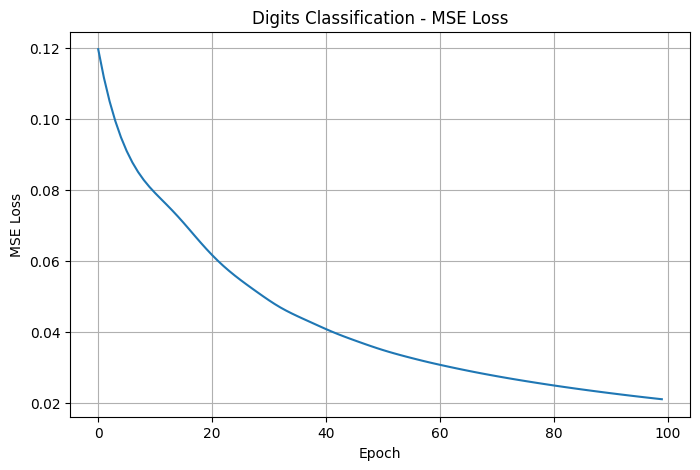

In [8]:
# Loss 변화 시각화
plt.figure(figsize=(8, 5))
plt.plot(loss_history)
plt.title("Digits Classification - MSE Loss")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.grid(True)
plt.show()
